# Визуализация данных: Matplotlib, Seaborn и Plotly


## Что мы сегодня научимся делать

На практике мы будем смотреть на данные как аналитики:

- строить базовые графики;
- понимать, **какой график подходит под какой вопрос**;
- исследовать распределения и взаимосвязи;
- сравнивать группы;
- находить выбросы;
- строить несколько графиков одновременно;
- делать интерактивные визуализации;
- замечать ошибки и манипуляции в графиках.

Мы познакомимся с тремя библиотеками:

- **Matplotlib** — фундамент и полный контроль над графиком;
- **Seaborn** — удобный анализ табличных данных;
- **Plotly** — интерактивные визуализации.

> Главная идея занятия: визуализация — это не украшение данных, а способ задавать им вопросы.

## 0. Подготовка окружения

Если библиотек нет, их можно установить:

```bash
pip install matplotlib seaborn plotly pandas
```

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

sns.set_theme(style="whitegrid")

print("Библиотеки успешно импортированы")

Библиотеки успешно импортированы


# 1. Зачем вообще визуализировать данные?

Начнём с набора данных о пингвинах.

Он содержит измерения нескольких видов пингвинов: массу тела, длину клюва, длину ласта, пол и остров обитания.

In [2]:
penguins = sns.load_dataset("penguins")
penguins.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [3]:
penguins.shape

(344, 7)

In [4]:
penguins.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


In [5]:
penguins.describe()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,200.915205,4201.754386
std,5.459584,1.974793,14.061714,801.954536
min,32.100000,13.100000,172.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000


### Один показатель против формы данных

Посчитаем среднюю массу пингвина.

In [6]:
penguins["body_mass_g"].mean()

np.float64(4201.754385964912)

Среднее число полезно, но оно не показывает:

- есть ли несколько групп;
- насколько велик разброс;
- есть ли выбросы;
- симметрично ли распределение.

Посмотрим на распределение визуально.

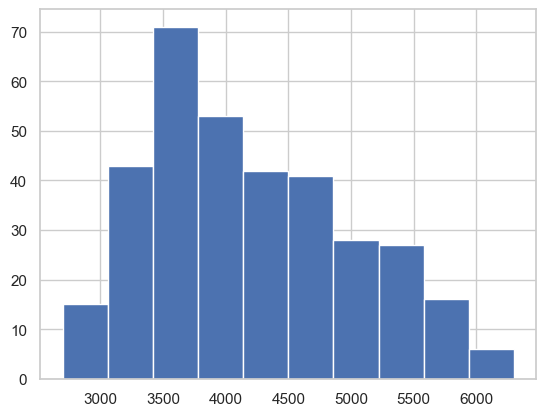

In [7]:
penguins["body_mass_g"].hist()
plt.show()

**Вопрос:**  
Что стало видно на графике такого, чего нельзя было понять по одному среднему значению?

# 2. Matplotlib: фундамент визуализации

`matplotlib` — одна из главных библиотек визуализации в Python.

Большая часть других библиотек визуализации так или иначе опирается на идеи Matplotlib.

Импорт обычно выглядит так:

```python
import matplotlib.pyplot as plt
```

## 2.1. Самый простой график

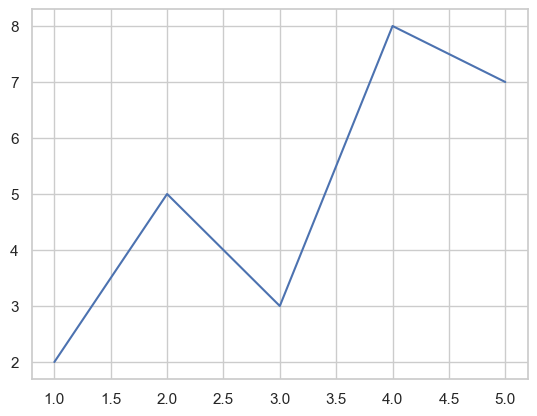

In [56]:
x = [1, 2, 3, 4, 5]
y = [2, 5, 3, 8, 7]

plt.plot(x, y)
plt.show()

Matplotlib может работать в двух стилях.

### Вариант 1 — через `plt`

```python
plt.plot(...)
plt.title(...)
```

### Вариант 2 — объектный стиль

```python
fig, ax = plt.subplots()
ax.plot(...)
```

Для серьёзных графиков второй подход обычно удобнее.

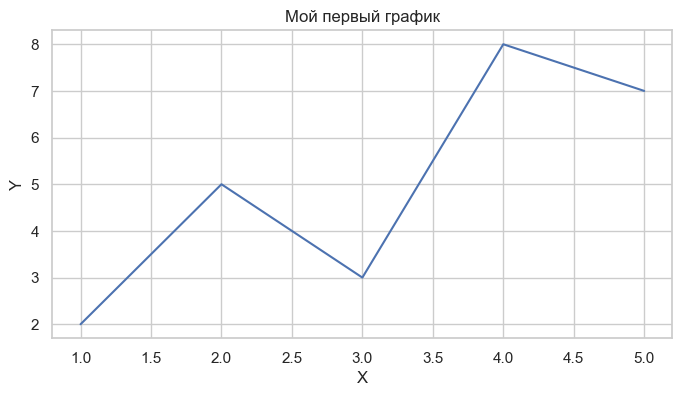

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(x, y)

ax.set_title("Мой первый график")
ax.set_xlabel("X")
ax.set_ylabel("Y")

plt.show()

## 2.2. Figure и Axes

Очень важные понятия:

- **Figure** — весь холст;
- **Axes** — конкретная область построения графика.

На одной Figure может быть несколько Axes.

<class 'matplotlib.figure.Figure'>
<class 'matplotlib.axes._axes.Axes'>


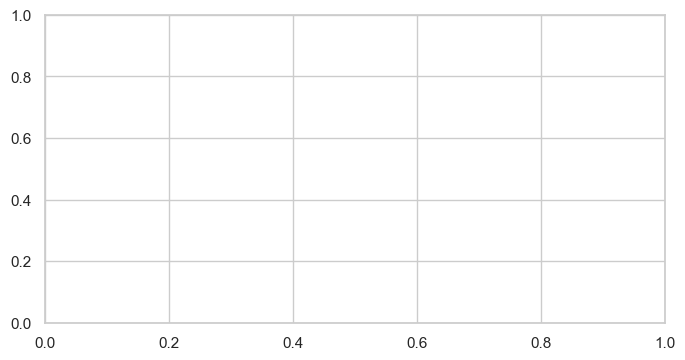

In [12]:
fig, ax = plt.subplots(figsize=(8, 4))

print(type(fig))
print(type(ax))

## 2.3. Как выбирать тип графика

Мы выбираем график не по принципу «какой красивее», а по вопросу.

| Вопрос | Тип графика |
|---|---|
| Как показатель меняется во времени? | line plot |
| Чем отличаются категории? | bar plot |
| Как распределены значения? | histogram |
| Есть ли связь между двумя признаками? | scatter plot |

## 2.4. Line plot — изменение показателя

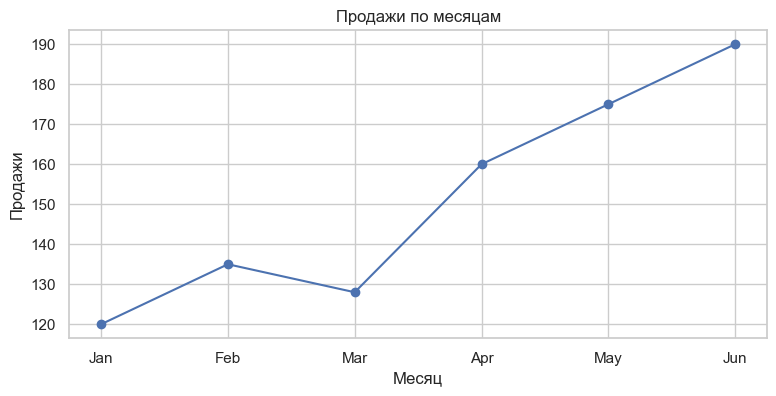

In [13]:
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun"]
sales = [120, 135, 128, 160, 175, 190]

fig, ax = plt.subplots(figsize=(9, 4))

ax.plot(months, sales, marker="o")

ax.set_title("Продажи по месяцам")
ax.set_xlabel("Месяц")
ax.set_ylabel("Продажи")

plt.show()

**Обратите внимание:** соединять точки линией имеет смысл, когда порядок по оси X действительно важен.

## 2.5. Bar chart — сравнение категорий

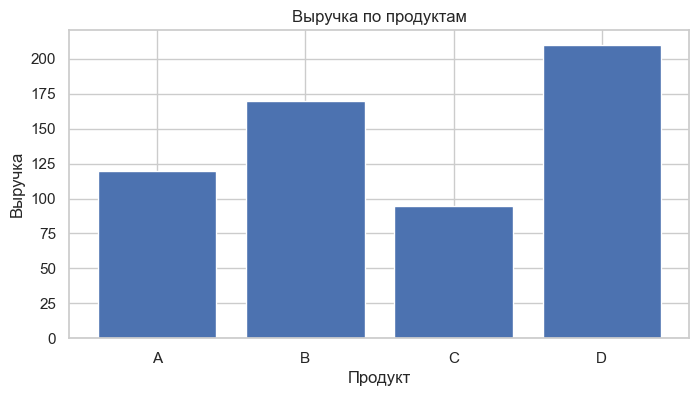

In [14]:
products = ["A", "B", "C", "D"]
revenue = [120, 170, 95, 210]

fig, ax = plt.subplots(figsize=(8, 4))

ax.bar(products, revenue)

ax.set_title("Выручка по продуктам")
ax.set_xlabel("Продукт")
ax.set_ylabel("Выручка")

plt.show()

## 2.6. Histogram — распределение значений

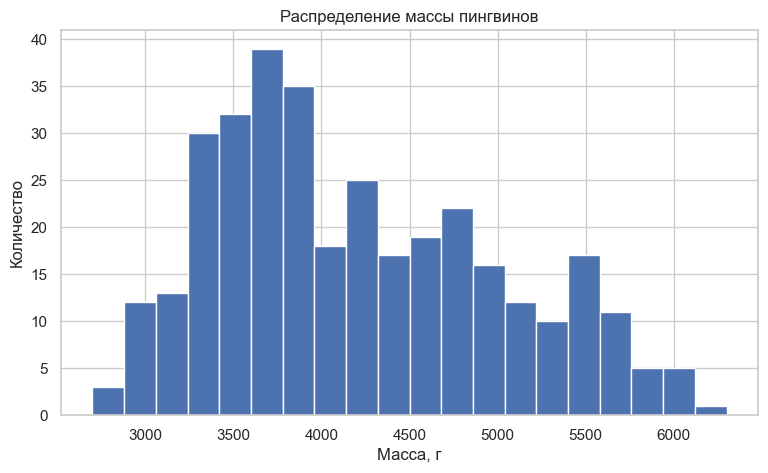

In [15]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    penguins["body_mass_g"].dropna(),
    bins=20
)

ax.set_title("Распределение массы пингвинов")
ax.set_xlabel("Масса, г")
ax.set_ylabel("Количество")

plt.show()

### Почему параметр `bins` важен?

Количество интервалов может сильно изменить впечатление от распределения.

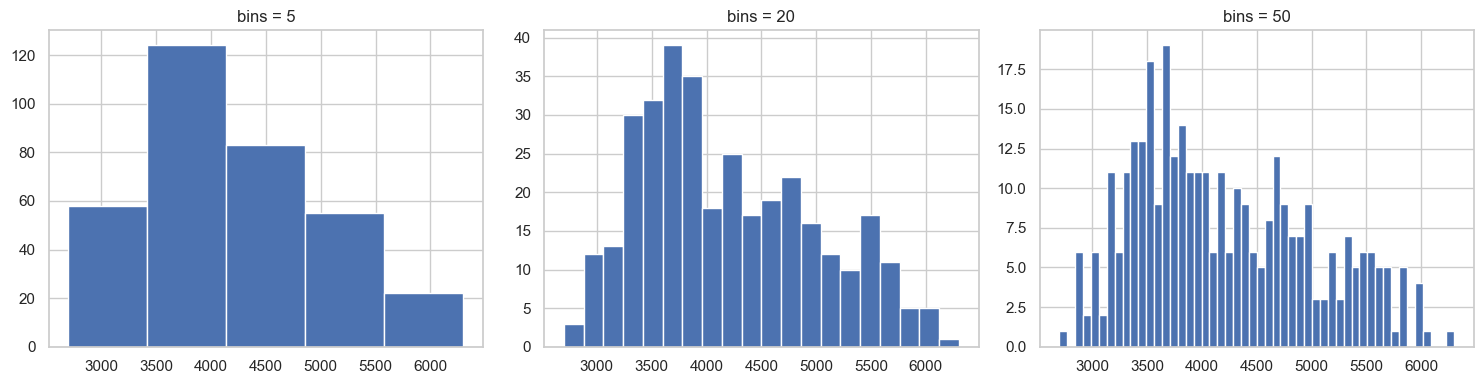

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(penguins["body_mass_g"].dropna(), bins=5)
axes[0].set_title("bins = 5")

axes[1].hist(penguins["body_mass_g"].dropna(), bins=20)
axes[1].set_title("bins = 20")

axes[2].hist(penguins["body_mass_g"].dropna(), bins=50)
axes[2].set_title("bins = 50")

plt.tight_layout()
plt.show()

**Вопрос студентам:**  
Какой график показывает структуру данных лучше?

Главная мысль:

> Параметры визуализации влияют на то, какие закономерности мы увидим.

## 2.7. Scatter plot — связь двух признаков

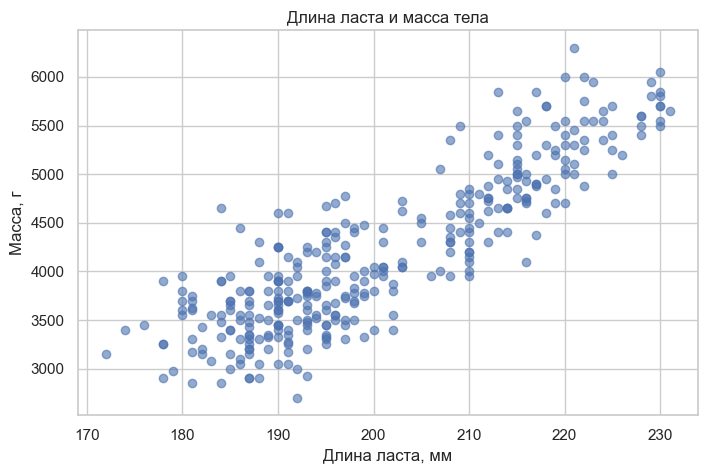

In [17]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    penguins["flipper_length_mm"],
    penguins["body_mass_g"],
    alpha=0.6
)

ax.set_title("Длина ласта и масса тела")
ax.set_xlabel("Длина ласта, мм")
ax.set_ylabel("Масса, г")

plt.show()

На графике заметна положительная связь:

**чем длиннее ласт, тем в среднем больше масса тела.**

Но важно помнить:

> Корреляция не доказывает причинность.

## 2.8. Несколько графиков одновременно

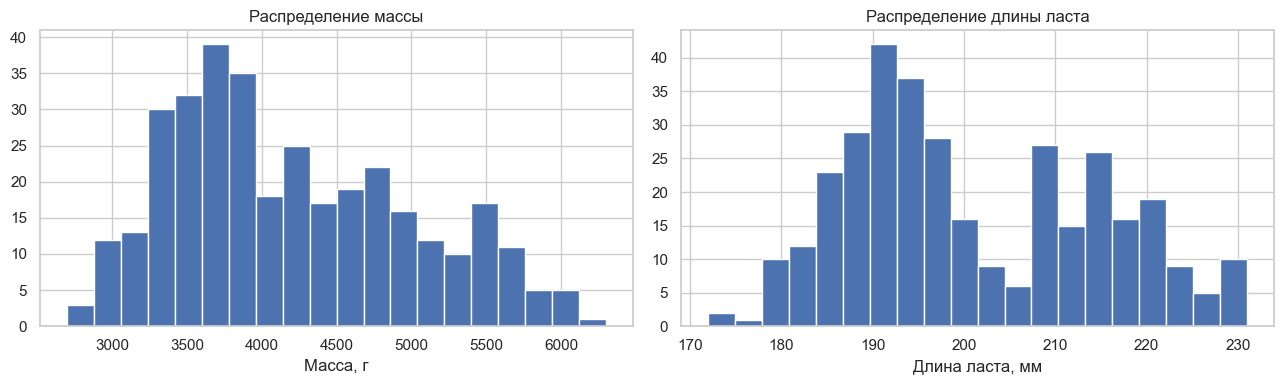

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(penguins["body_mass_g"].dropna(), bins=20)
axes[0].set_title("Распределение массы")
axes[0].set_xlabel("Масса, г")

axes[1].hist(penguins["flipper_length_mm"].dropna(), bins=20)
axes[1].set_title("Распределение длины ласта")
axes[1].set_xlabel("Длина ласта, мм")

plt.tight_layout()
plt.show()

# 3. Как графики могут вводить в заблуждение

Визуализация — мощный инструмент, но им легко манипулировать.

## 3.1. Обрезанная ось

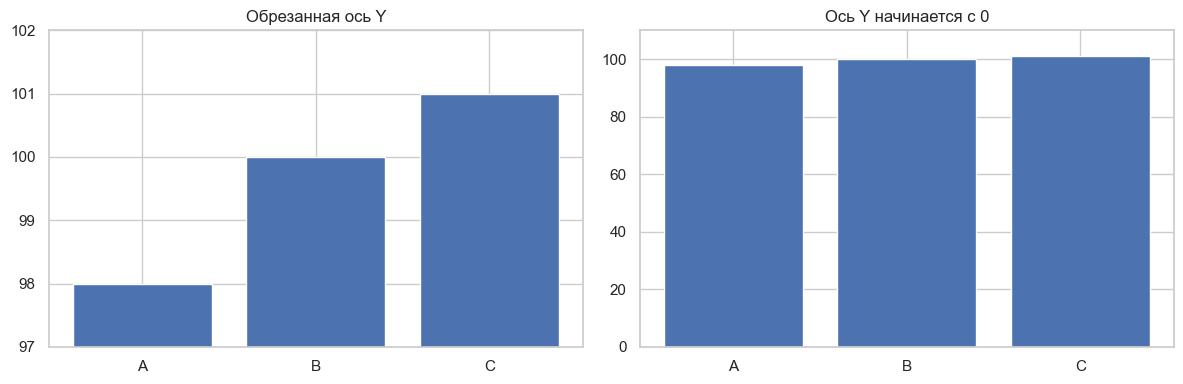

In [19]:
values = [98, 100, 101]
labels = ["A", "B", "C"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(labels, values)
axes[0].set_ylim(97, 102)
axes[0].set_title("Обрезанная ось Y")

axes[1].bar(labels, values)
axes[1].set_ylim(0, 110)
axes[1].set_title("Ось Y начинается с 0")

plt.tight_layout()
plt.show()

Данные одинаковые, но визуальное впечатление сильно различается.

**Вопрос:** на левом графике кажется, что C намного больше A?

Это хороший пример того, почему нужно смотреть на шкалу оси.

## 3.2. Overplotting

Если точек очень много, они начинают перекрывать друг друга.

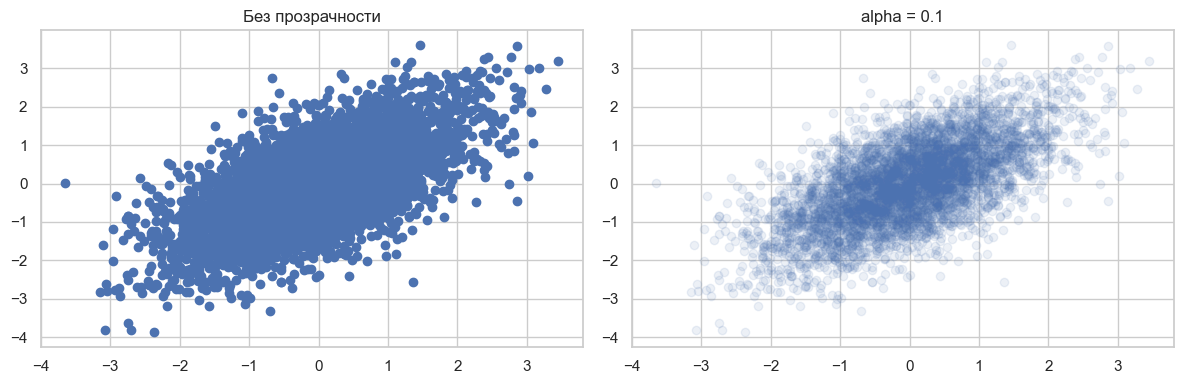

In [20]:
rng = np.random.default_rng(42)

x_big = rng.normal(size=5000)
y_big = x_big * 0.7 + rng.normal(scale=0.8, size=5000)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(x_big, y_big)
axes[0].set_title("Без прозрачности")

axes[1].scatter(x_big, y_big, alpha=0.1)
axes[1].set_title("alpha = 0.1")

plt.tight_layout()
plt.show()

Мы не изменили данные, но сделали структуру заметнее.

Это важный принцип:

> Хорошая визуализация помогает человеку увидеть информацию, а не просто рисует все точки.

# 4. Seaborn: исследовательский анализ данных

`Seaborn` работает поверх Matplotlib, но гораздо удобнее взаимодействует с `pandas.DataFrame`.

Главное преимущество:

```python
sns.scatterplot(
    data=df,
    x="column_1",
    y="column_2"
)
```

Не нужно вручную вытаскивать каждый столбец.

## 4.1. Сравним Matplotlib и Seaborn

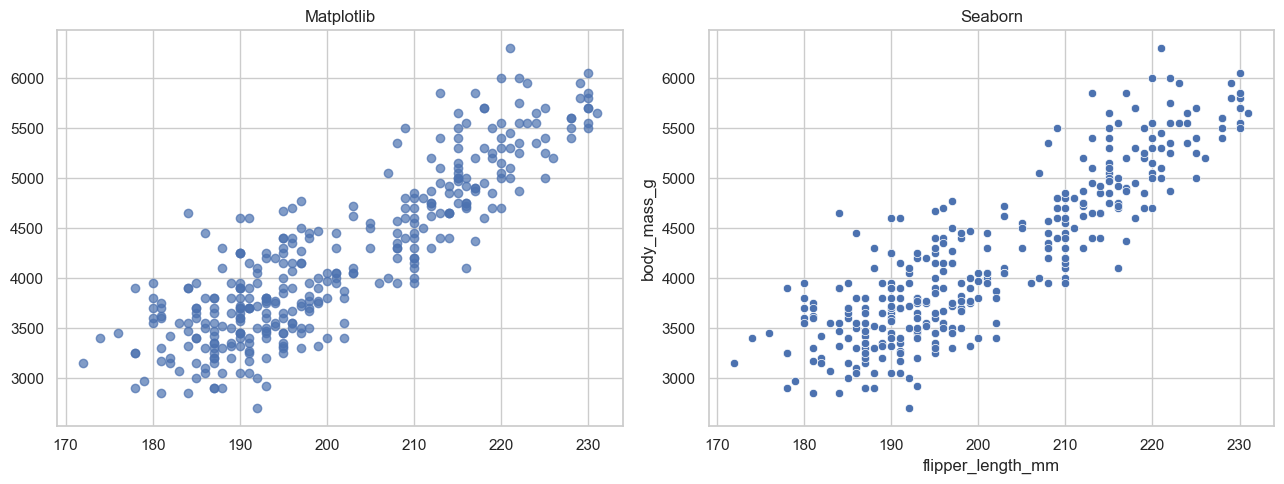

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(
    penguins["flipper_length_mm"],
    penguins["body_mass_g"],
    alpha=0.7
)
axes[0].set_title("Matplotlib")

sns.scatterplot(
    data=penguins,
    x="flipper_length_mm",
    y="body_mass_g",
    ax=axes[1]
)
axes[1].set_title("Seaborn")

plt.tight_layout()
plt.show()

## 4.2. `hue`: добавляем третье измерение

Теперь раскрасим точки по виду пингвина.

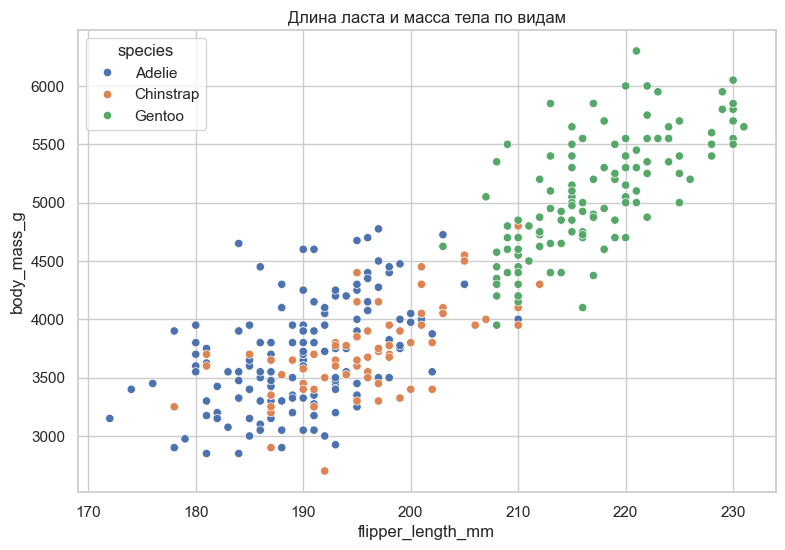

In [22]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=penguins,
    x="flipper_length_mm",
    y="body_mass_g",
    hue="species"
)

plt.title("Длина ласта и масса тела по видам")
plt.show()

Теперь становится видно, что данные образуют несколько групп.

Это пример важной идеи визуализации: одна точка может кодировать несколько признаков.

Возможные визуальные каналы:

- положение X;
- положение Y;
- цвет;
- форма;
- размер.

## 4.3. `style`: ещё один признак

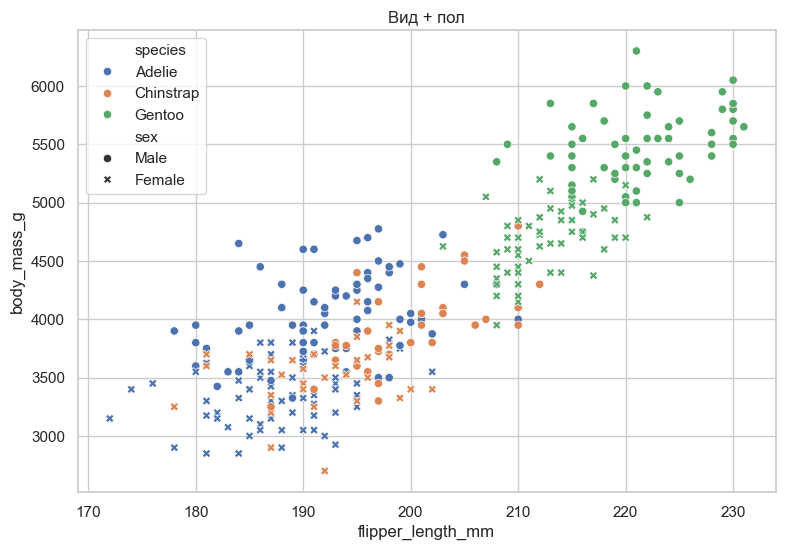

In [23]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=penguins,
    x="flipper_length_mm",
    y="body_mass_g",
    hue="species",
    style="sex"
)

plt.title("Вид + пол")
plt.show()

## 4.4. Распределения: `histplot`

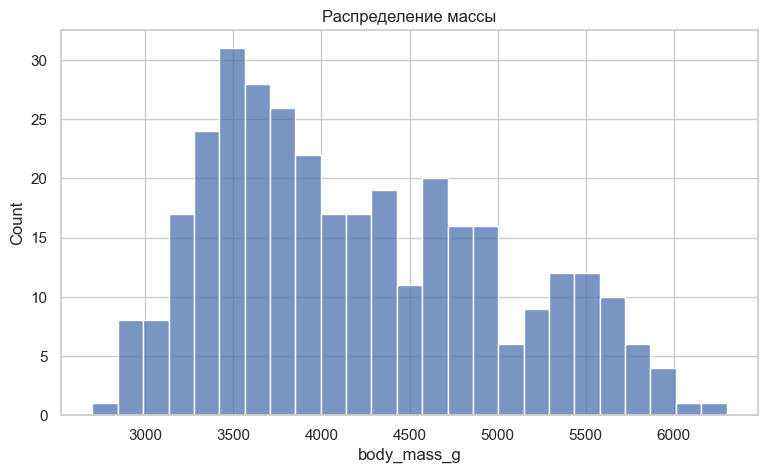

In [24]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=penguins,
    x="body_mass_g",
    bins=25
)

plt.title("Распределение массы")
plt.show()

Добавим виды пингвинов.

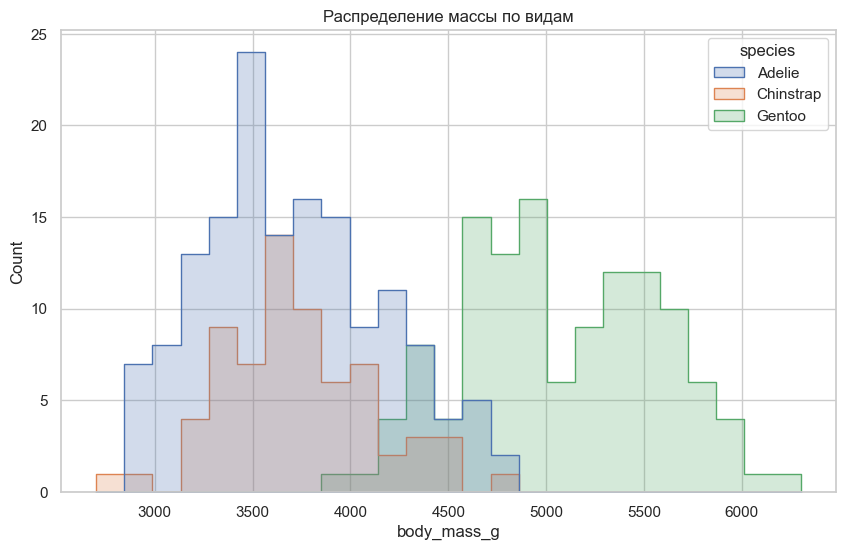

In [25]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=penguins,
    x="body_mass_g",
    hue="species",
    bins=25,
    element="step"
)

plt.title("Распределение массы по видам")
plt.show()

## 4.5. KDE — сглаженное распределение

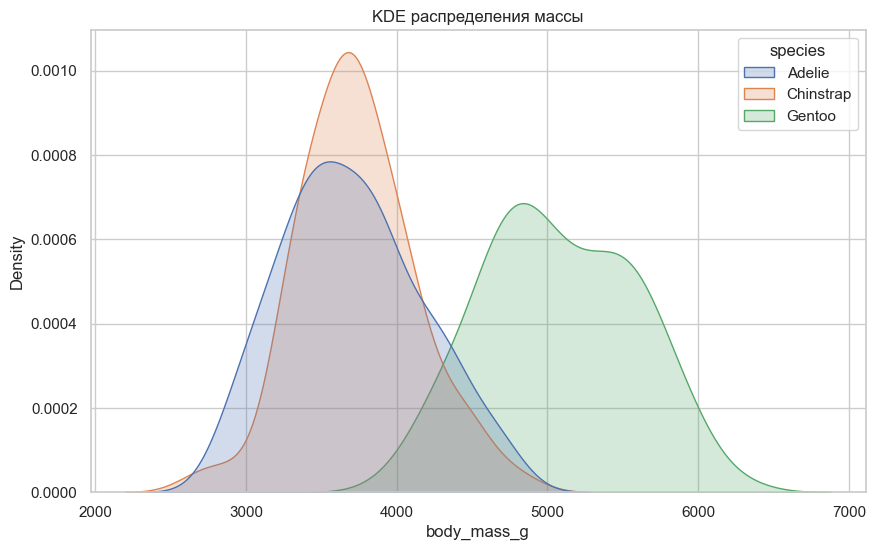

In [26]:
plt.figure(figsize=(10, 6))

sns.kdeplot(
    data=penguins,
    x="body_mass_g",
    hue="species",
    fill=True,
    common_norm=False
)

plt.title("KDE распределения массы")
plt.show()

KDE можно воспринимать как сглаженную оценку формы распределения.

Пока математические детали нам не нужны — важно понять идею.

# 5. Категории и распределения

Для сравнения групп особенно полезны `boxplot` и `violinplot`.

## 5.1. Boxplot

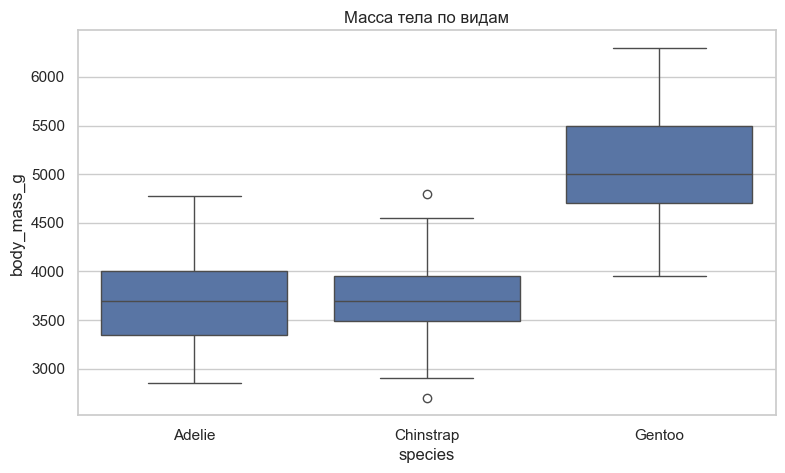

In [ ]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=penguins,
    x="species",
    y="body_mass_g"
)

plt.title("Масса тела по видам")
plt.show()

### Что показывает boxplot?

- центральная линия — медиана;
- коробка — диапазон от Q1 до Q3;
- высота коробки — IQR;
- «усы» — типичный диапазон значений;
- отдельные точки могут указывать на выбросы.

Boxplot очень часто используется в анализе данных.

## 5.2. Violin plot

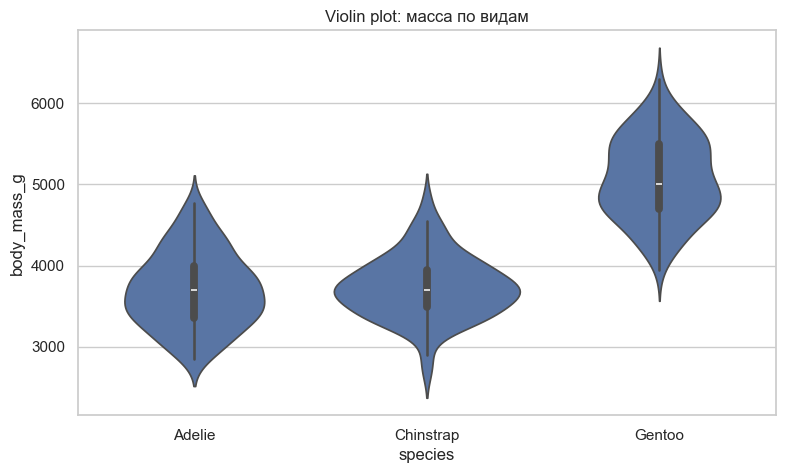

In [28]:
plt.figure(figsize=(9, 5))

sns.violinplot(
    data=penguins,
    x="species",
    y="body_mass_g",
    inner="box"
)

plt.title("Violin plot: масса по видам")
plt.show()

Violin plot показывает не только квартильную структуру, но и форму распределения.

**Вопрос:**  
Что легче сравнивать на boxplot, а что — на violinplot?

# 6. Линия тренда: `regplot`

Построим scatter plot и автоматически добавим линейную зависимость.

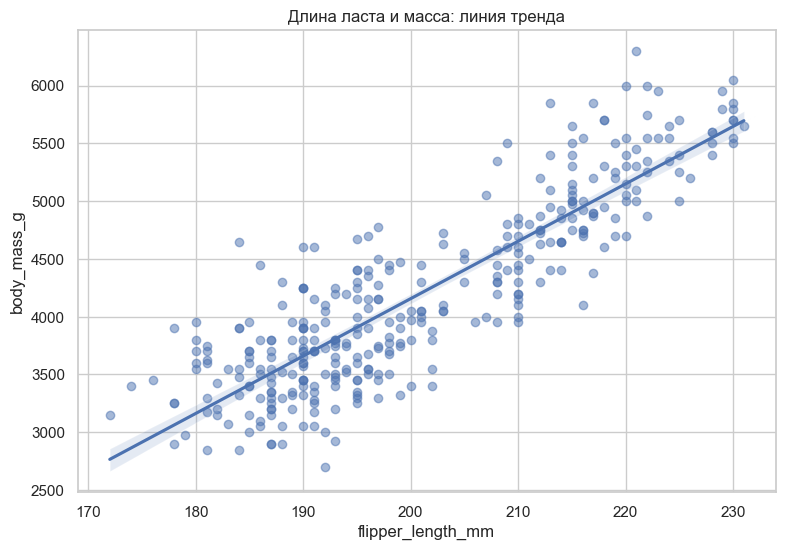

In [29]:
plt.figure(figsize=(9, 6))

sns.regplot(
    data=penguins,
    x="flipper_length_mm",
    y="body_mass_g",
    scatter_kws={"alpha": 0.5}
)

plt.title("Длина ласта и масса: линия тренда")
plt.show()

Через несколько занятий мы сами научимся строить такую линию математически.

Это уже прямой мост к теме **линейной регрессии**.

# 7. Pairplot: быстрый обзор всего датасета

`pairplot` строит попарные графики сразу для нескольких числовых признаков.

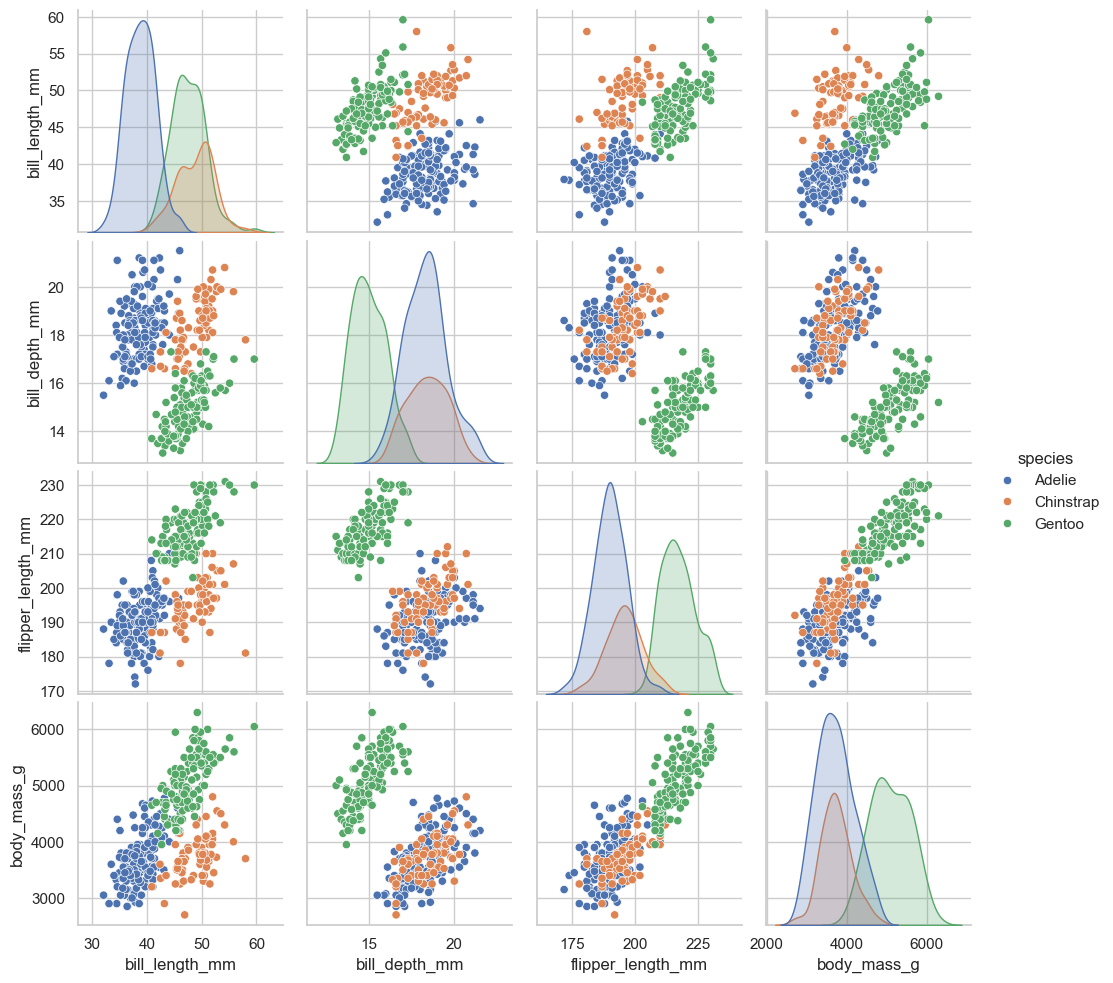

In [58]:
sns.pairplot(
    penguins.dropna(),
    hue="species"
)

plt.show()

Это один из самых полезных графиков для первичного анализа данных.

**Вопрос:**

Если бы нужно было определить вид пингвина по измерениям, какие признаки выглядят наиболее полезными?

# 8. Корреляционная матрица и heatmap

In [31]:
numeric_penguins = penguins.select_dtypes(include="number")

corr = numeric_penguins.corr()
corr

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
bill_length_mm,1.000000,-0.235053,0.656181,0.595110
bill_depth_mm,-0.235053,1.000000,-0.583851,-0.471916
flipper_length_mm,0.656181,-0.583851,1.000000,0.871202
body_mass_g,0.595110,-0.471916,0.871202,1.000000


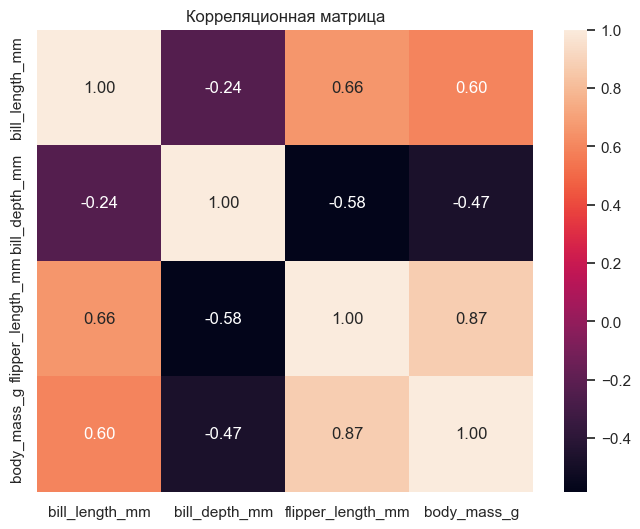

In [32]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f"
)

plt.title("Корреляционная матрица")
plt.show()

Коэффициент корреляции находится примерно в диапазоне от -1 до 1.

- **1** — сильная положительная линейная связь;
- **0** — линейной связи практически нет;
- **-1** — сильная отрицательная линейная связь.

Важно:

> корреляция не означает причинность.

# 9. Facets: разделяем данные на несколько панелей

Иногда лучше не пытаться разместить все группы на одном графике.

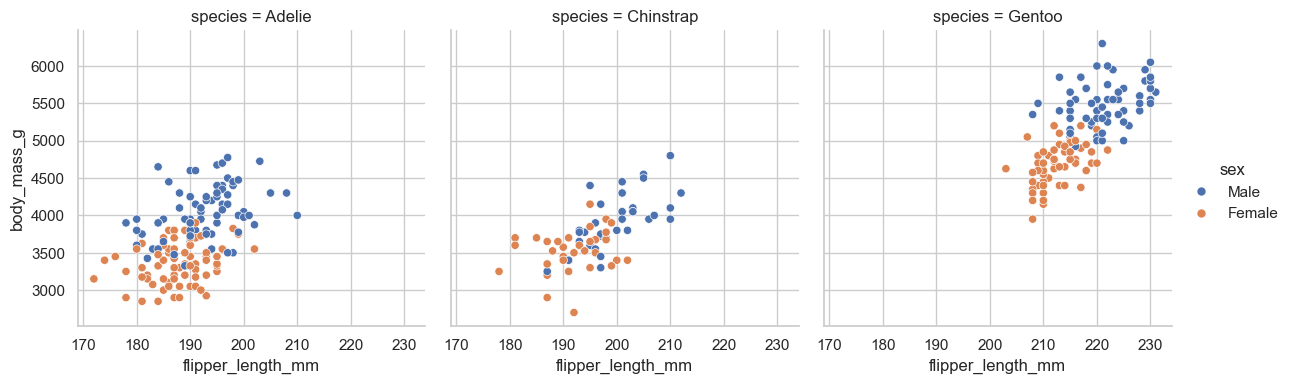

In [33]:
sns.relplot(
    data=penguins,
    x="flipper_length_mm",
    y="body_mass_g",
    col="species",
    hue="sex",
    height=4
)

plt.show()

Такой подход называется **small multiples**: один тип графика повторяется для разных подмножеств данных.

# 10. Ещё один датасет: чаевые в ресторане

Посмотрим на датасет `tips`.

In [34]:
tips = sns.load_dataset("tips")
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [35]:
tips.describe(include="all")

,total_bill,tip,sex,smoker,day,time,size
count,244.000000,244.000000,244,244,244,244,244.000000
unique,NaN,NaN,2,2,4,2,NaN
top,NaN,NaN,Male,No,Sat,Dinner,NaN
freq,NaN,NaN,157,151,87,176,NaN
mean,19.785943,2.998279,NaN,NaN,NaN,NaN,2.569672
std,8.902412,1.383638,NaN,NaN,NaN,NaN,0.951100
min,3.070000,1.000000,NaN,NaN,NaN,NaN,1.000000
25%,13.347500,2.000000,NaN,NaN,NaN,NaN,2.000000
50%,17.795000,2.900000,NaN,NaN,NaN,NaN,2.000000
75%,24.127500,3.562500,NaN,NaN,NaN,NaN,3.000000


## 10.1. В какие дни счёт выше?

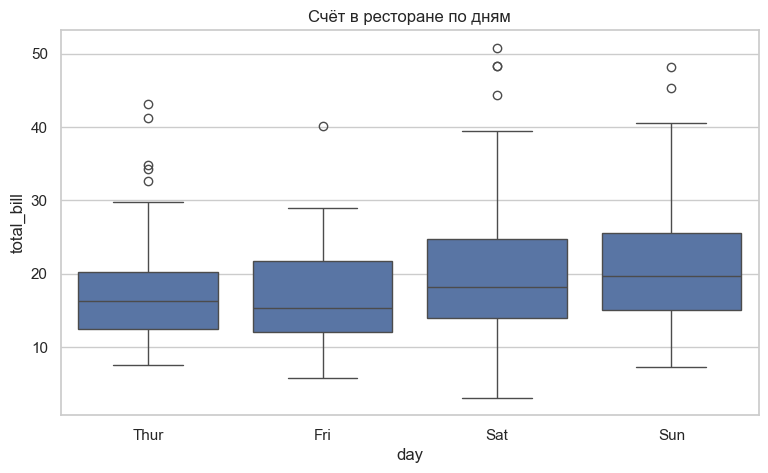

In [36]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=tips,
    x="day",
    y="total_bill"
)

plt.title("Счёт в ресторане по дням")
plt.show()

## 10.2. Как связан размер счёта и чаевые?

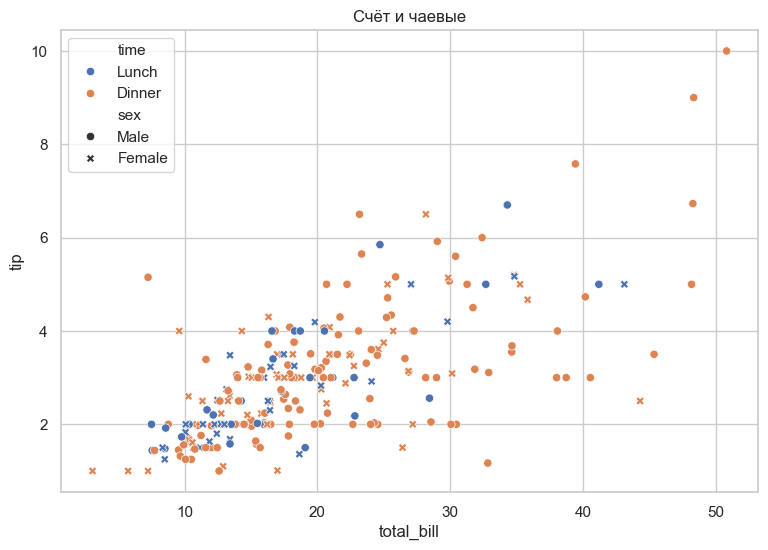

In [37]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=tips,
    x="total_bill",
    y="tip",
    hue="time",
    style="sex"
)

plt.title("Счёт и чаевые")
plt.show()

## 10.3. Чаевые в процентах

Создадим новый признак.

In [38]:
tips = tips.copy()
tips["tip_pct"] = tips["tip"] / tips["total_bill"] * 100

tips[["total_bill", "tip", "tip_pct"]].head()

,total_bill,tip,tip_pct
0,16.99,1.01,5.944673
1,10.34,1.66,16.054159
2,21.01,3.50,16.658734
3,23.68,3.31,13.978041
4,24.59,3.61,14.680765


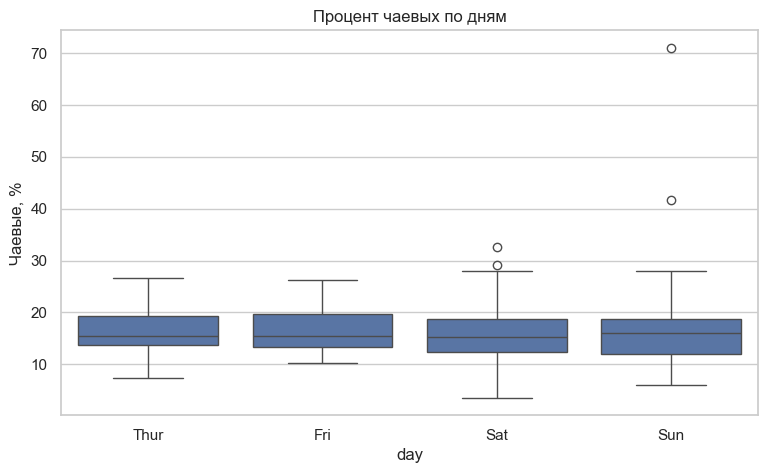

In [39]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=tips,
    x="day",
    y="tip_pct"
)

plt.title("Процент чаевых по дням")
plt.ylabel("Чаевые, %")
plt.show()

Этот пример показывает важную мысль:

Иногда абсолютная величина хуже отвечает на вопрос, чем производный показатель.

# 11. Plotly: интерактивная визуализация

Теперь перейдём к `Plotly`.

В отличие от обычной статической картинки, здесь пользователь может:

- наводить курсор;
- смотреть значения;
- увеличивать области;
- перемещать график;
- включать и выключать категории;
- выбирать точки.

## 11.1. Первый интерактивный scatter plot

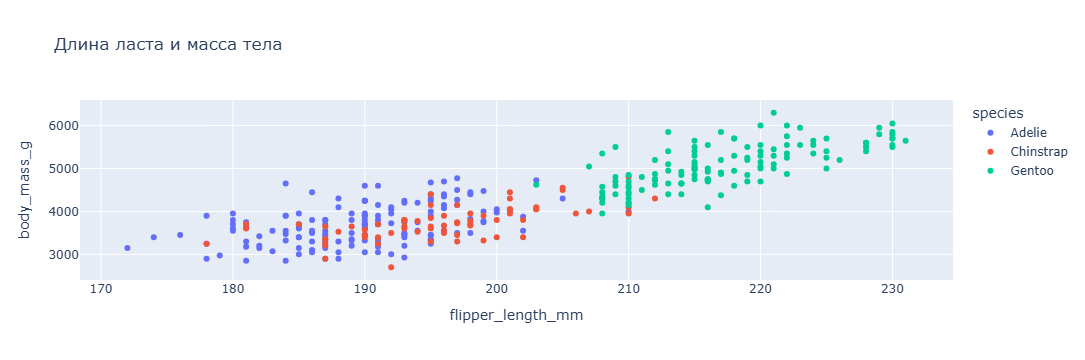

In [40]:
fig = px.scatter(
    penguins,
    x="flipper_length_mm",
    y="body_mass_g",
    color="species",
    title="Длина ласта и масса тела"
)

fig.show()

Попробуйте:

- навести курсор на точку;
- увеличить участок;
- двойным щелчком вернуть масштаб;
- нажать на название вида в легенде.

## 11.2. Добавляем данные в tooltip

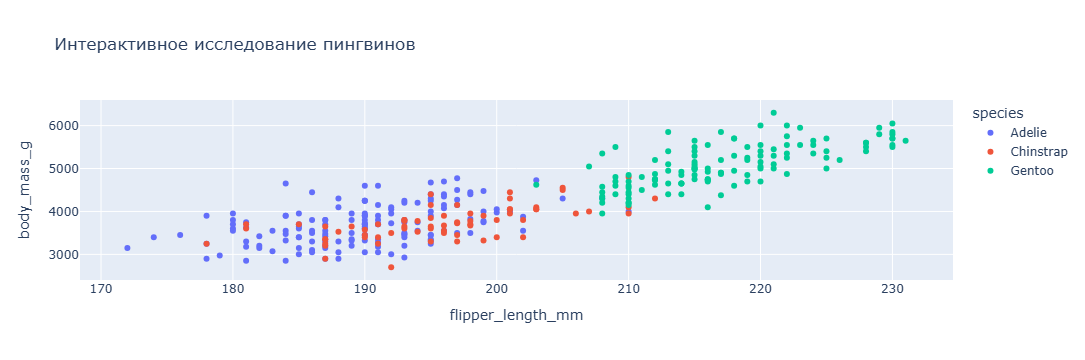

In [41]:
fig = px.scatter(
    penguins,
    x="flipper_length_mm",
    y="body_mass_g",
    color="species",
    hover_data=[
        "island",
        "sex",
        "bill_length_mm",
        "bill_depth_mm"
    ],
    title="Интерактивное исследование пингвинов"
)

fig.show()

Теперь график уже начинает работать как небольшой интерфейс для исследования данных.

## 11.3. Размер точки как дополнительный признак

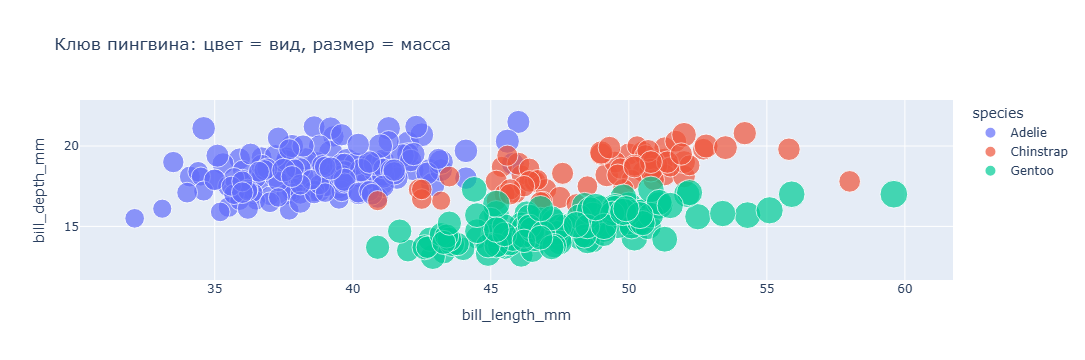

In [42]:
plot_penguins = penguins.dropna(
    subset=["bill_length_mm", "bill_depth_mm", "body_mass_g", "species"]
)

fig = px.scatter(
    plot_penguins,
    x="bill_length_mm",
    y="bill_depth_mm",
    color="species",
    size="body_mass_g",
    hover_data=["island", "sex"],
    title="Клюв пингвина: цвет = вид, размер = масса"
)

fig.show()

В одном графике мы кодируем:

- X — длина клюва;
- Y — глубина клюва;
- цвет — вид;
- размер — массу тела;
- tooltip — дополнительные признаки.

# 12. Plotly и категориальные данные

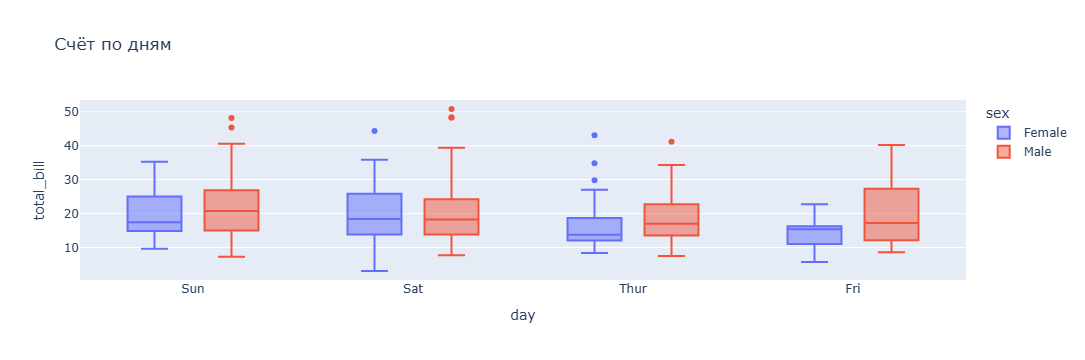

In [43]:
fig = px.box(
    tips,
    x="day",
    y="total_bill",
    color="sex",
    title="Счёт по дням"
)

fig.show()

## 12.1. Интерактивный violin plot

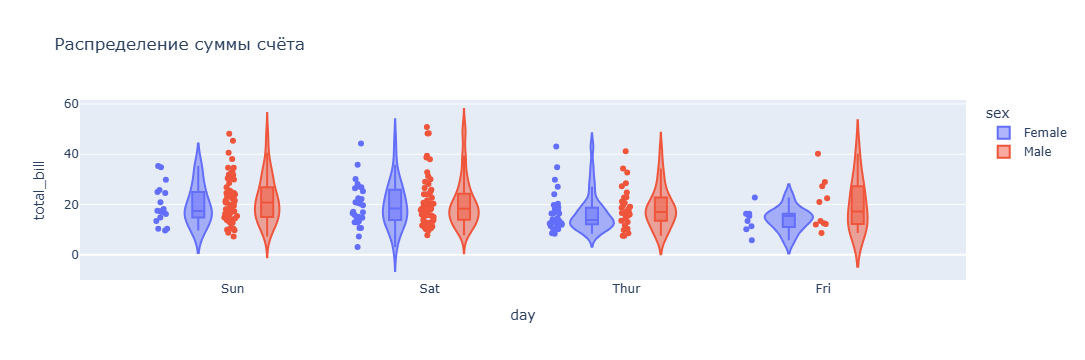

In [44]:
fig = px.violin(
    tips,
    x="day",
    y="total_bill",
    color="sex",
    box=True,
    points="all",
    title="Распределение суммы счёта"
)

fig.show()

Здесь особенно удобно изучать отдельные наблюдения через наведение курсора.

# 13. Финальный wow-момент: Gapminder

В Plotly встроен известный датасет Gapminder.

В нём есть:

- страны;
- годы;
- население;
- ВВП на человека;
- ожидаемая продолжительность жизни.

In [45]:
gapminder = px.data.gapminder()
gapminder.head()

,country,continent,year,lifeExp,pop,gdpPercap,iso_alpha,iso_num
0,Afghanistan,Asia,1952,28.801,8425333,779.445314,AFG,4
1,Afghanistan,Asia,1957,30.332,9240934,820.853030,AFG,4
2,Afghanistan,Asia,1962,31.997,10267083,853.100710,AFG,4
3,Afghanistan,Asia,1967,34.020,11537966,836.197138,AFG,4
4,Afghanistan,Asia,1972,36.088,13079460,739.981106,AFG,4


In [46]:
gapminder["year"].min(), gapminder["year"].max()

(1952, 2007)

Построим анимированный график.

В нём:

- X — ВВП на человека;
- Y — продолжительность жизни;
- цвет — континент;
- размер — население;
- подпись — страна;
- время — год.

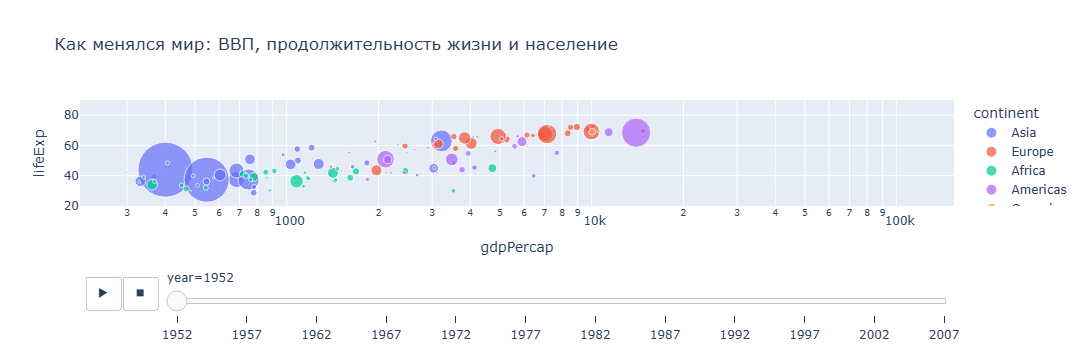

In [47]:
fig = px.scatter(
    gapminder,
    x="gdpPercap",
    y="lifeExp",
    size="pop",
    color="continent",
    hover_name="country",
    animation_frame="year",
    animation_group="country",
    log_x=True,
    size_max=60,
    range_y=[20, 90],
    title="Как менялся мир: ВВП, продолжительность жизни и население"
)

fig.show()

Этот пример хорошо показывает, как визуализация превращает таблицу из тысяч строк в понятную историю.

> Мы не просто смотрим на данные — мы наблюдаем изменение целой системы во времени.

# 14. Matplotlib vs Seaborn vs Plotly

Эти библиотеки не обязательно конкурируют друг с другом.

| Библиотека | Когда особенно полезна |
|---|---|
| **Matplotlib** | полный контроль, сложная кастомизация, научные графики |
| **Seaborn** | быстрый EDA, DataFrame, статистические графики |
| **Plotly** | интерактивность, презентации, dashboards |

Типичный рабочий процесс может выглядеть так:

```text
pandas
  ↓
Seaborn → быстрый анализ
  ↓
Matplotlib → тонкая настройка
  ↓
Plotly → интерактивная версия
```

# 15. Шпаргалка: какой график выбрать?

### Хотим увидеть распределение

- histogram
- KDE
- boxplot
- violinplot

### Хотим сравнить категории

- barplot
- boxplot
- violinplot

### Хотим увидеть связь

- scatterplot
- regplot

### Хотим увидеть изменение во времени

- line plot

### Хотим исследовать сразу много признаков

- pairplot
- heatmap

### Хотим интерактивность

- Plotly

# 16. Пять частых ошибок визуализации

1. **Обрезанная ось**, преувеличивающая различия.
2. **Слишком много цветов** и визуального шума.
3. **Слишком много категорий** на одном графике.
4. **Overplotting** — точки перекрывают друг друга.
5. Выбор графика по красоте, а не по смыслу.

Хороший вопрос перед построением графика:

> **Что именно я хочу узнать из данных?**

# 17. Финальный мини-анализ

Попробуем ответить на несколько вопросов только с помощью визуализации.

### Вопрос 1

Какие признаки лучше всего разделяют виды пингвинов?

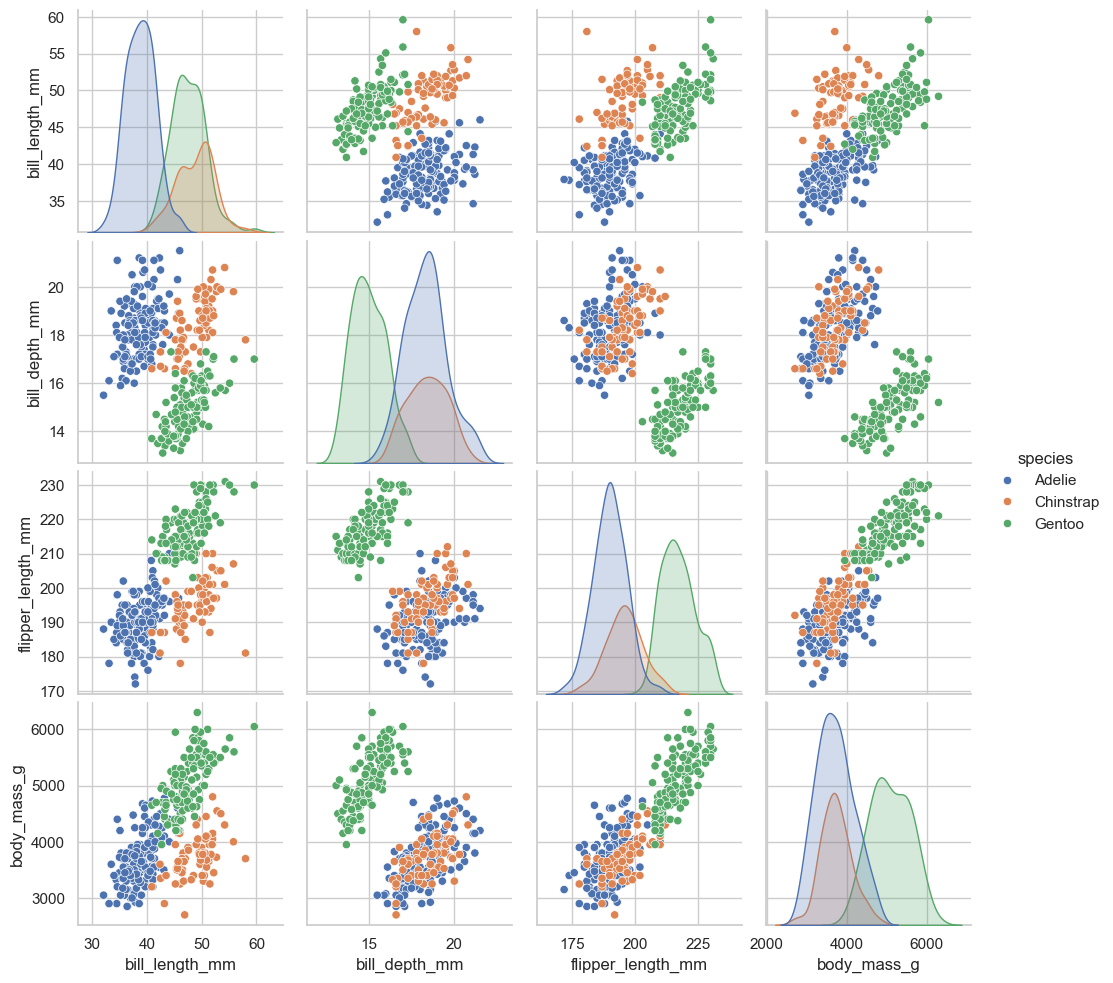

In [48]:
sns.pairplot(
    penguins.dropna(),
    vars=[
        "bill_length_mm",
        "bill_depth_mm",
        "flipper_length_mm",
        "body_mass_g"
    ],
    hue="species"
)

plt.show()

### Вопрос 2

Есть ли различия между самцами и самками по массе?

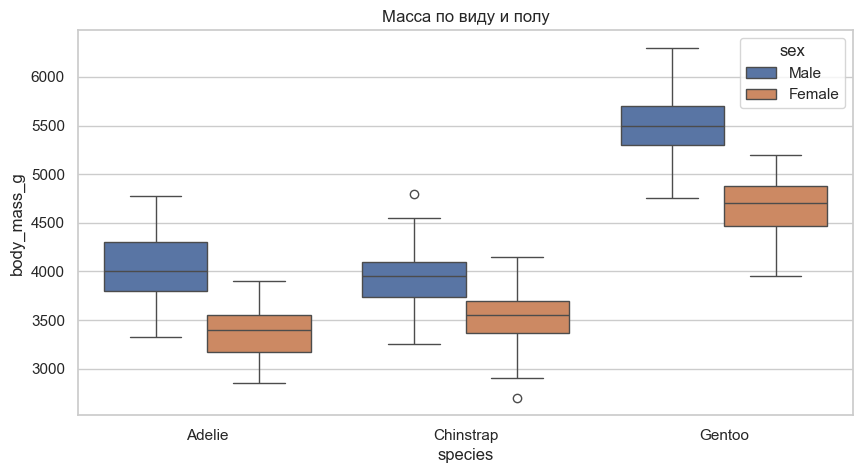

In [49]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=penguins,
    x="species",
    y="body_mass_g",
    hue="sex"
)

plt.title("Масса по виду и полу")
plt.show()

### Вопрос 3

Насколько связаны длина ласта и масса внутри каждого вида?

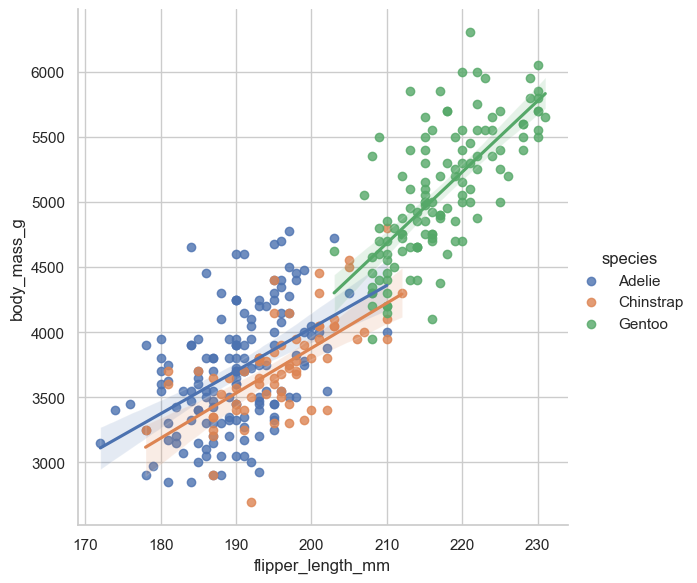

In [50]:
sns.lmplot(
    data=penguins,
    x="flipper_length_mm",
    y="body_mass_g",
    hue="species",
    height=6
)

plt.show()

# 18. Главное, что нужно запомнить

Сегодня мы не просто изучали команды библиотек.

Мы учились **читать данные визуально**.

Последовательность хорошего анализа:

```text
вопрос
  ↓
данные
  ↓
подходящий тип графика
  ↓
визуализация
  ↓
наблюдение
  ↓
новый вопрос
```

Именно так обычно начинается исследовательский анализ данных — **EDA (Exploratory Data Analysis)**.

---

## Связь с машинным обучением

Сегодня мы глазами искали:

- группы;
- зависимости;
- выбросы;
- различия между классами;
- информативные признаки.

В машинном обучении мы будем учить алгоритмы находить закономерности автоматически.

> **Визуализация помогает понять данные до того, как мы начнём обучать модель.**

# Дополнительные демонстрации
Ниже — несколько необязательных примеров.

## Jointplot

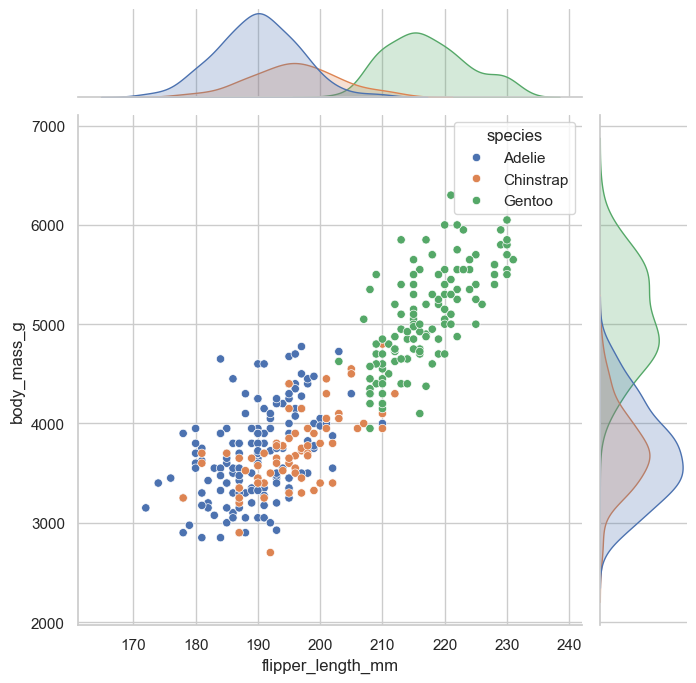

In [51]:
sns.jointplot(
    data=penguins,
    x="flipper_length_mm",
    y="body_mass_g",
    hue="species",
    height=7
)

plt.show()

## Countplot

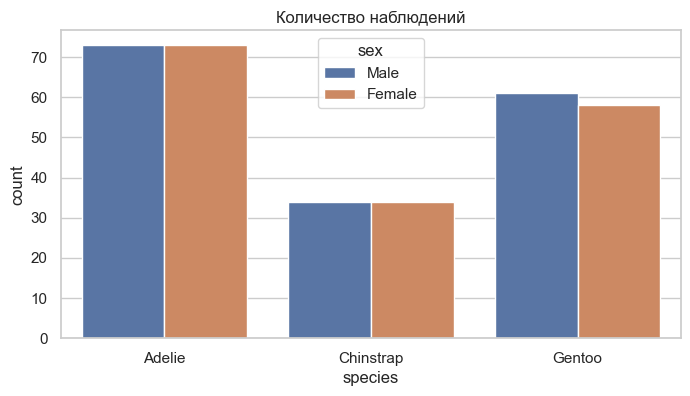

In [52]:
plt.figure(figsize=(8, 4))

sns.countplot(
    data=penguins,
    x="species",
    hue="sex"
)

plt.title("Количество наблюдений")
plt.show()

## Stripplot поверх boxplot

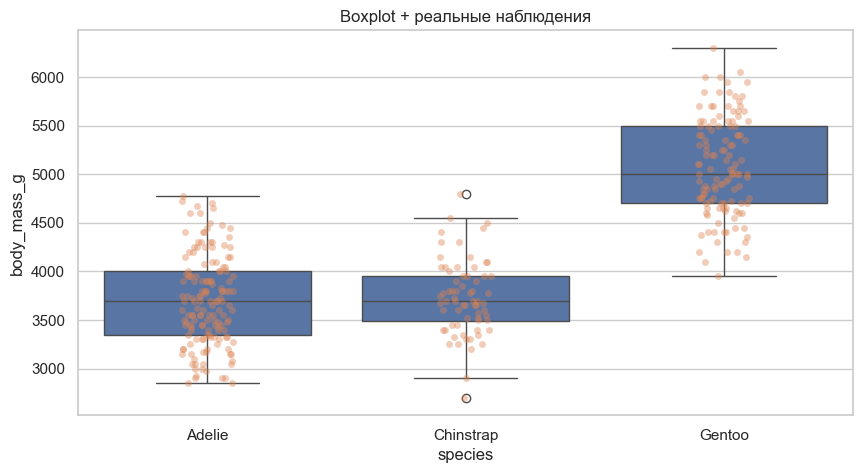

In [53]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=penguins,
    x="species",
    y="body_mass_g"
)

sns.stripplot(
    data=penguins,
    x="species",
    y="body_mass_g",
    alpha=0.4
)

plt.title("Boxplot + реальные наблюдения")
plt.show()

## Plotly histogram

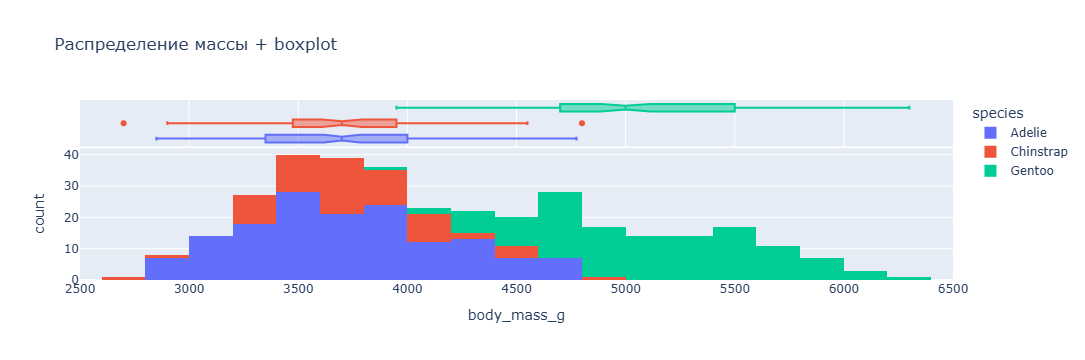

In [54]:
fig = px.histogram(
    penguins,
    x="body_mass_g",
    color="species",
    marginal="box",
    title="Распределение массы + boxplot"
)

fig.show()

### Заключительный вопрос

Если завтра вам дадут незнакомый датасет, какой график вы построите первым?

Правильного универсального ответа нет.

Сначала нужно спросить:

> **Что я хочу узнать об этих данных?**